# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3384 Володченко Матвей Валентинович. Вариант №4.

## Цель работы

 Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### Свёртка реакции системы на произвольный сигнал

* Выражает выходной сигнал $y(n)$ через входной $x(n)$ и импульсную характеристику $h(n)$.
  $$y(n) = x(n) * h(n) = \sum_{k=-\infty}^{\infty} x(k) h(n-k)$$

### Передаточная функция
* Отношение Z-образа выхода к Z-образу входа при нулевых начальных условиях.
  $$H(z) = \frac{Y(z)}{X(z)} = \frac{\sum_{m=0}^{M} b_m z^{-m}}{\sum_{k=0}^{N} a_k z^{-k}}$$

* **Нули**: корни числителя.
* **Полюсы**: корни знаменателя.

### АЧХ и ФЧХ

Комплексная частотная характеристика при $z = e^{j\omega}$:
$$H(e^{j\omega}) = A(\omega) e^{j \phi(\omega)}$$

* **Амплитудно-частотная характеристика (АЧХ)**:
  $$A(\omega) = |H(e^{j\omega})|$$
* **Фазо-частотная характеристика (ФЧХ)**:
  $$\phi(\omega) = \arg H(e^{j\omega})$$

### Рекурсивное звено 2-го порядка

* **Разностное уравнение**: определяет систему с $N=2, M=2$ в явном виде относительно текущего отсчета.
  $$y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2)$$

### ДПФ

Для последовательности $x(n)$ длины $N$ ($n, k \in [0, N-1]$):

* **Прямое ДПФ**:
  $$X(k) = \sum_{n=0}^{N-1} x(n) e^{-j \frac{2 \pi}{N} k n}$$

* **Обратное ДПФ**:
  $$x(n) = \frac{1}{N} \sum_{k=0}^{N-1} X(k) e^{j \frac{2 \pi}{N} k n}$$

### Равенство Парсеваля

* Устанавливает сохранение энергии сигнала во временной и частотной областях.
  $$\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X(k)|^2$$

### Частотные шкалы
* **Дискретная частота (номер отсчёта спектра):** $k = 0, 1, \dots, N - 1$
* **Нормированная частота:** 
  $$\tilde{f} = \frac{k}{N}, \quad \omega = \frac{2\pi k}{N} \text{ (круговая, рад/отсчёт)}$$
* **Абсолютная (физическая) частота:** 
  $$f = \frac{k \cdot f_d}{N} \text{ (Гц)}$$

## Постановка задачи

 Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

In [1]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
import cmath
from fractions import Fraction

Расчёт переменных для первой части практической работы варианта 4.

In [2]:
Nvar = 4
b0 = 0.5 + 0.02 * Nvar
b1 = b0 * ( (-1) ** (Nvar + 1) ) * ( 0.9822 + 0.0178 * Nvar )
b2 = b0 * ( 0.8 + (Nvar % 5) * 0.2 )
a0 = 1
a1 = ( (-1) ** (Nvar + 1) ) * ( 0.7778 + 0.025 * Nvar )
a2 = 0.64 + 0.006 * Nvar
N1 = 20 + Nvar % 10
N2 = 30 + Nvar % 10
fd = 1000 * Nvar

print(f"Nvar     = {Nvar};\nb[0,1,2] = {b0}, {b1}, {b2};\na[0,1,2] = {a0}, {a1}, {a2};\nN[1,2]   = {N1}, {N2};\nfd       = {fd};")

a = np.array([a0, a1, a2])
b = np.array([b0, b1, b2])
print(f"\na = {a};\nb = {b};")

Nvar     = 4;
b[0,1,2] = 0.58, -0.6109719999999998, 0.9279999999999999;
a[0,1,2] = 1, -0.8778, 0.664;
N[1,2]   = 24, 34;
fd       = 4000;

a = [ 1.     -0.8778  0.664 ];
b = [ 0.58     -0.610972  0.928   ];


1.1

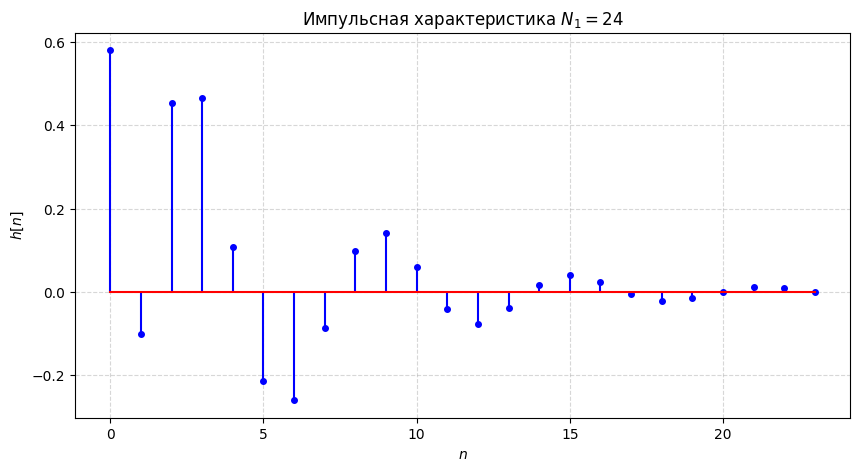

In [3]:
n = np.arange(N1)
D = np.zeros(N1)
D[0] = 1.0
h = signal.lfilter(b, a, D)

plt.figure(figsize=(10, 5), dpi=100)
markerline, stemlines, baseline = plt.stem(n, h, linefmt='b-', markerfmt='bo', basefmt='r-')
plt.setp(markerline, markersize=4)

plt.title(f'Импульсная характеристика $N_1 = {N1}$', fontsize=12)
plt.xlabel('$n$', fontsize=10)
plt.ylabel('$h[n]$', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

Аналитическая формула импульсной характеристики:
$$H(z) = \frac{0.58 - 0.610972z^{-1} + 0.928z^{-2}}{1 - 0.8778z^{-1} + 0.664z^{-2}} \Rightarrow y(n) = 0.58x(n) - 0.610972x(n - 1) + 0.928x(n - 2) + 0.8778y(n - 1) - 0.664y(n - 2),$$

Импульсная характеристика это реакция системы на цифровой единичный импульс: $x(n) = u_0(n)$

$$h(n) = 0.58u_0(n) - 0.610972u_0(n - 1) + 0.928u_0(n - 2) + 0.8778h(n - 1) - 0.664h(n - 2)$$

Теоретическая длина импульсной характеристики бесконечна, но на практике ее длительность ограничена. Практическую длину определяют по времени затухания сигнала до пренебрежимо малой величины.

1.2

In [4]:
x = np.zeros(N2)
border = int(N2 / 2) # или N2//2 или ещё что то... потом подумать, что имелось ввиду в условии...
x[:border] = 1.0

y1 = np.convolve(h, x)

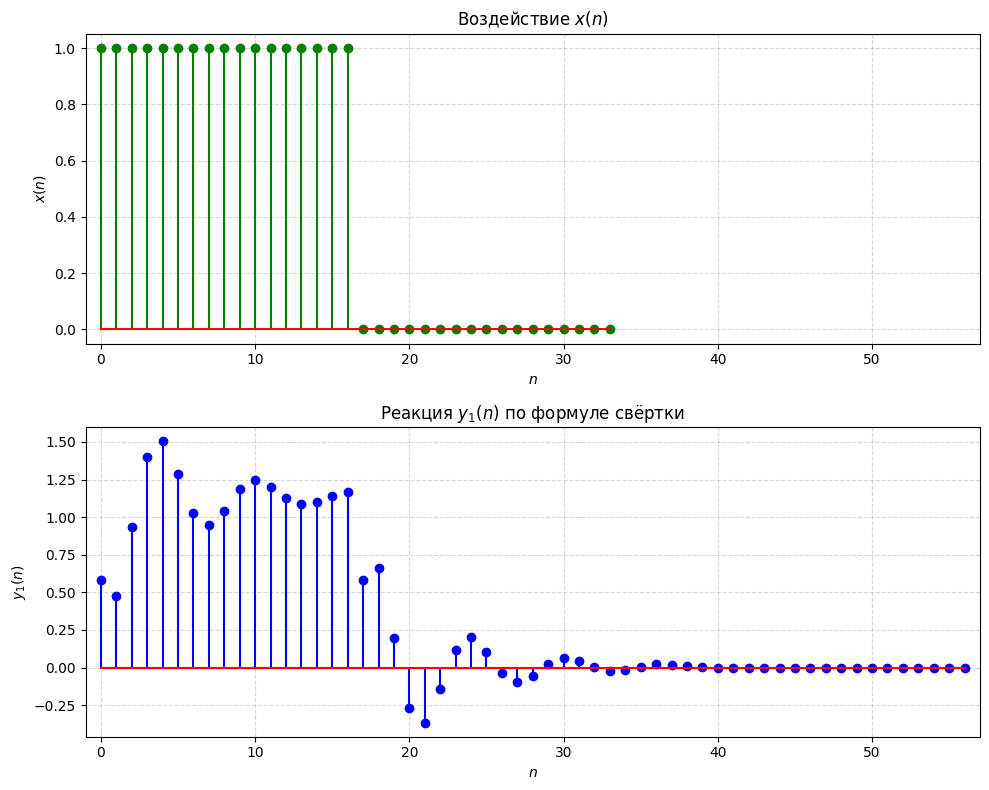

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.stem(np.arange(N2), x, linefmt='g-', markerfmt='go', basefmt='r-')
ax1.set_title(f'Воздействие $x(n)$', fontsize=12)
ax1.set_xlabel('$n$', fontsize=10)
ax1.set_ylabel('$x(n)$', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.stem(np.arange(len(y1)), y1, linefmt='b-', markerfmt='bo', basefmt='r-')
ax2.set_title(f'Реакция $y_1(n)$ по формуле свёртки', fontsize=12)
ax2.set_xlabel('$n$', fontsize=10)
ax2.set_ylabel('$y_1(n)$', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

ax1.set_xlim(-1, len(y1))
ax2.set_xlim(-1, len(y1))
plt.tight_layout()
plt.show()

#### Пояснения:
* **Чему равна длина импульса $x$:**  
   $N_2 = 34$ отсчета.

* **Чему равна длина свёртки аналитически и по графику:**  
  Аналитически длина полной линейной свёртки рассчитывается по формуле:  
  $$N_{св} = N_1 + N_2 - 1 = 24 + 34 - 1 = 57 \text{ отсчетов.}$$

* **Почему её ограничивают до длины воздействия:**  
  На практике график реакции обрезают до длины воздействия ($N_2 = 34$), чтобы сопоставить входной и выходной сигналы. Отсчеты свёртки за пределами $N_2$ (от 34 до 56) представляют собой затухающие колебания.

1.3

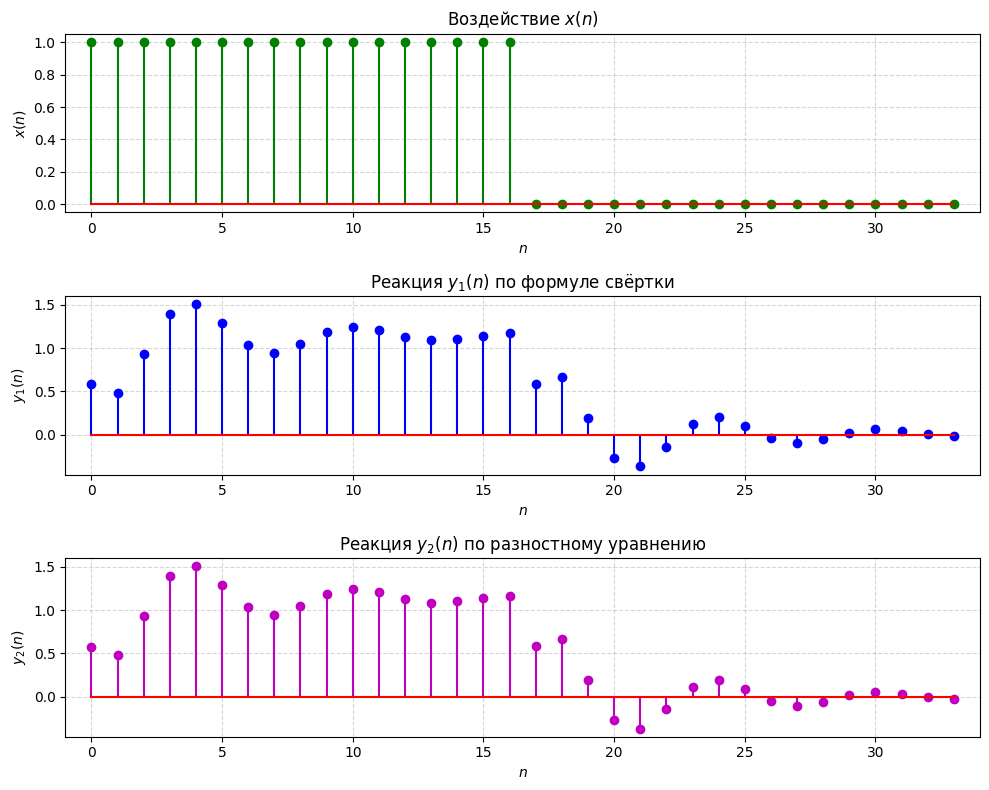

In [6]:
y2 = signal.lfilter(b, a, x)

fig, (ax67, ax1, ax2) = plt.subplots(3, 1, figsize=(10, 8), dpi=100)
ax67.stem(np.arange(N2), x, linefmt='g-', markerfmt='go', basefmt='r-')
ax67.set_title(f'Воздействие $x(n)$', fontsize=12)
ax67.set_xlabel('$n$', fontsize=10)
ax67.set_ylabel('$x(n)$', fontsize=10)
ax67.grid(True, linestyle='--', alpha=0.5)

ax1.stem(np.arange(len(y1))[:len(y2)], y1[:len(y2)], linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title(f'Реакция $y_1(n)$ по формуле свёртки', fontsize=12)
ax1.set_xlabel('$n$', fontsize=10)
ax1.set_ylabel('$y_1(n)$', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.stem(np.arange(len(y2)), y2, linefmt='m-', markerfmt='mo', basefmt='r-')
ax2.set_title(f'Реакция $y_2(n)$ по разностному уравнению', fontsize=12)
ax2.set_xlabel('$n$', fontsize=10)
ax2.set_ylabel('$y_2(n)$', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

ax67.set_xlim(-1, len(y2))
ax1.set_xlim(-1, len(y2))
ax2.set_xlim(-1, len(y2))
plt.tight_layout()
plt.show()

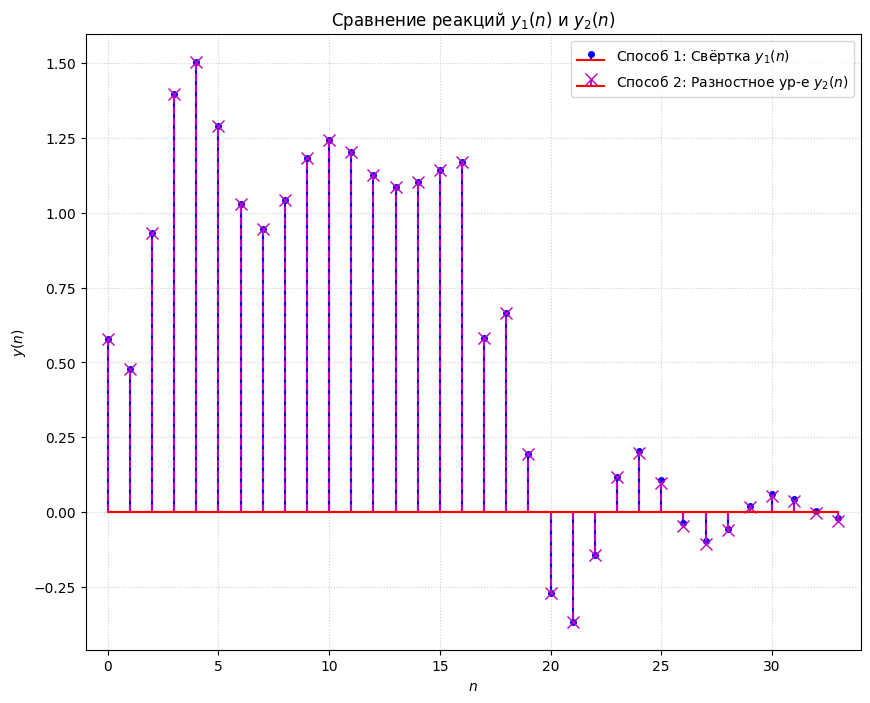

In [7]:
plt.figure(figsize=(10, 8), dpi=100)

marker1, stem1, base1 = plt.stem(np.arange(len(y1))[:len(y2)], y1[:len(y2)], linefmt='b-', markerfmt='bo', basefmt='r-', label='Способ 1: Свёртка $y_1(n)$')
plt.setp(marker1, markersize=4)

marker2, stem2, base2 = plt.stem(np.arange(len(y2)), y2, linefmt='m--', markerfmt='mx', basefmt='r-', label='Способ 2: Разностное ур-е $y_2(n)$')
plt.setp(marker2, markersize=8, markeredgewidth=1)

plt.title('Сравнение реакций $y_1(n)$ и $y_2(n)$', fontsize=12)
plt.xlabel('$n$', fontsize=10)
plt.ylabel('$y(n)$', fontsize=10)
plt.xlim(-1, len(y2))
plt.grid(True, linestyle=':', alpha=0.6)

plt.legend(loc='upper right', fontsize=10)
plt.show()

Разностное уравнение рекурсивного звена 2-го порядка имеет вид:

$$y_2(n) = 0.58x(n) - 0.610972x(n - 1) + 0.928x(n - 2) + 0.8778y_2(n - 1) - 0.664y_2(n - 2)$$

* **Чему равны длины воздействия и реакции:**  
  * Длина воздействия $x(n)$ равна $N_2 = 34$ отсчетам.
  * Длина реакции $y_2(n)$ при расчете через разностное уравнение ограничена длительностью входного массива и также равна $N_2 = 34$ отсчетам.

* **Сравнение графиков реакций $y_1(n)$ и $y_2(n)$:**  
  * **На интервале от $0$ до $N_2 - 1$ (от 0 до 33):** Графики практически идентичны, с поправкой на точность вычислений.
  * **После отсчета $N_2 - 1$ (начиная с 34-го):** График реакции по разностному уравнению $y_2(n)$ обрывается из-за окончания входного сигнала. График свёртки $y_1(n)$ продолжает рассчитывать значения вплоть до 56-го отсчета, показывая затухающие колебания системы.
  * **Вывод по визуализации:** Если принудительно ограничить отображение осей обоих графиков временным окном воздействия длины $N_2 = 34$ отсчета, то они становятся визуально неразличимы.


1.4

In [8]:
def print_apm(name, numbers, ofs):
    for i, c in enumerate(numbers):
        real_part = c.real
        imag_part = c.imag

        r, theta = cmath.polar(c)
        theta_over_pi = theta / np.pi

        print(f"{name}{i+1}{ofs}:")
        print(f"  - Алгебраическая форма:  {real_part:+.4f} {imag_part:+.4f}j")
        print(f"  - Показательная форма:   {r:.4f} * e^(j * {theta_over_pi:+.4f}*pi)")
        print(f"  - Модуль = {r:.4f}, rad = {theta_over_pi:+.4f} * pi")
    print()

zeros, poles, gain = signal.tf2zpk(b, a)
print_apm("Нуль z(", zeros, ")")
print_apm("Полюс p(", poles, ")")

Нуль z(1):
  - Алгебраическая форма:  +0.5267 +1.1500j
  - Показательная форма:   1.2649 * e^(j * +0.3633*pi)
  - Модуль = 1.2649, rad = +0.3633 * pi
Нуль z(2):
  - Алгебраическая форма:  +0.5267 -1.1500j
  - Показательная форма:   1.2649 * e^(j * -0.3633*pi)
  - Модуль = 1.2649, rad = -0.3633 * pi

Полюс p(1):
  - Алгебраическая форма:  +0.4389 +0.6866j
  - Показательная форма:   0.8149 * e^(j * +0.3189*pi)
  - Модуль = 0.8149, rad = +0.3189 * pi
Полюс p(2):
  - Алгебраическая форма:  +0.4389 -0.6866j
  - Показательная форма:   0.8149 * e^(j * -0.3189*pi)
  - Модуль = 0.8149, rad = -0.3189 * pi



Подставляя найденные значения нулей и полюсов в показательной форме вид функции:

$$H(z) = 0.58 \cdot \frac{(z - 1.2649e^{j \cdot 0.3633\pi})(z - 1.2649e^{-j \cdot 0.3633\pi})}{(z - 0.8149e^{j \cdot 0.3189\pi})(z - 0.8149e^{-j \cdot 0.3189\pi})}$$

1.5

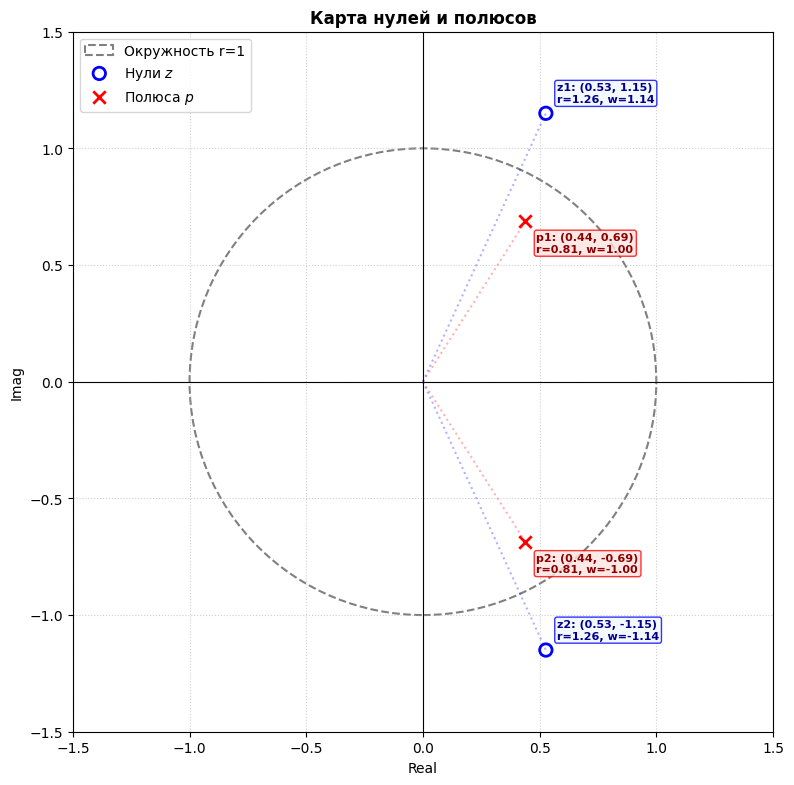

In [9]:
plt.figure(figsize=(8, 8), dpi=100)

circle = plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--', linewidth=1.5, label='Окружность r=1')
plt.gca().add_patch(circle)


plt.scatter(zeros.real, zeros.imag, marker='o', s=80, facecolors='none', edgecolors='blue', linewidths=2, label='Нули $z$', zorder=5)
plt.scatter(poles.real, poles.imag, marker='x', s=80, color='red', linewidths=2, label='Полюса $p$', zorder=5)

for i, z in enumerate(zeros):
    r = np.abs(z)
    w_angle = np.angle(z)
    plt.plot([0, z.real], [0, z.imag], color='blue', linestyle=':', alpha=0.3)
    
    label_z = f'z{i+1}: ({z.real:.2f}, {z.imag:.2f})\nr={r:.2f}, w={w_angle:.2f}'
    plt.annotate(label_z, (z.real, z.imag), xytext=(8, 8), textcoords='offset points',
                 fontsize=8, color='darkblue', fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', fc='aliceblue', ec='blue', alpha=0.8))


for i, p in enumerate(poles):
    r = np.abs(p)
    w_angle = np.angle(p)
    plt.plot([0, p.real], [0, p.imag], color='red', linestyle=':', alpha=0.3)
    
    label_p = f'p{i+1}: ({p.real:.2f}, {p.imag:.2f})\nr={r:.2f}, w={w_angle:.2f}'
    plt.annotate(label_p, (p.real, p.imag), xytext=(8, -22), textcoords='offset points',
                 fontsize=8, color='darkred', fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.2', fc='mistyrose', ec='red', alpha=0.8))

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Карта нулей и полюсов', fontsize=12, fontweight='bold')
plt.xlabel('Real', fontsize=10)
plt.ylabel('Imag', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()


Т.к. |p1|=|p2|<1, то звено устойчиво.
Результаты совпадают с пунктом 1.4.

1.6

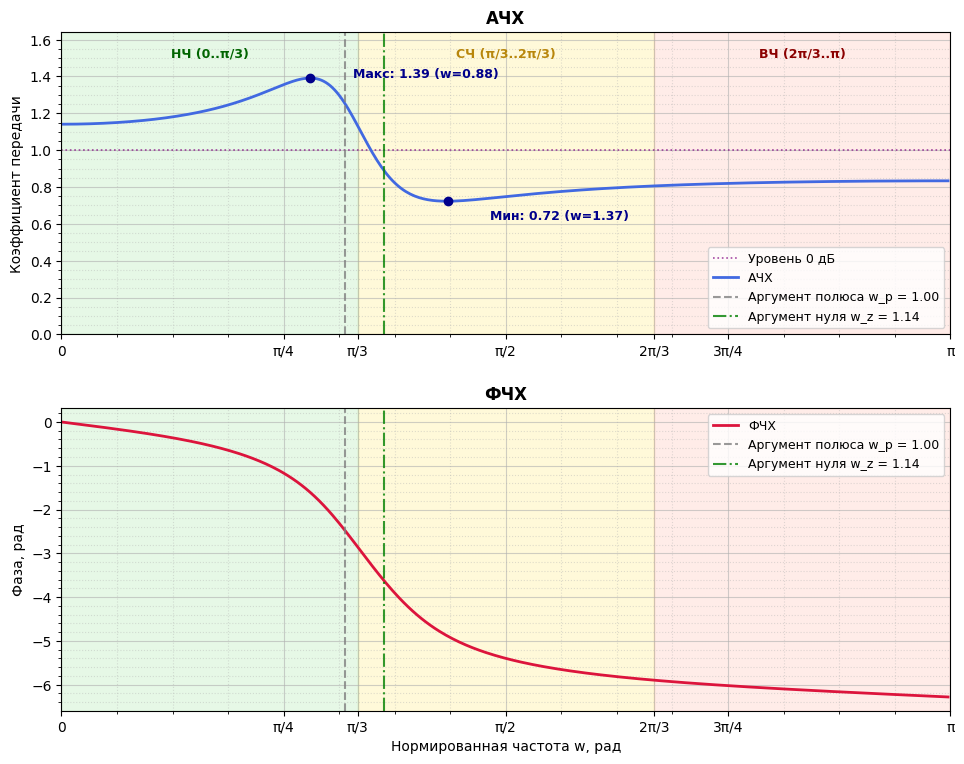

In [10]:
w, H_freq = signal.freqz(b, a, worN=400) # Что бы показать резкость спада н->п выставляется worN=22
ach = np.abs(H_freq)
fch = np.angle(H_freq)
fch = np.unwrap(fch) # Убираем скачки за pi(ГОПЧ=0..pi)

idx_max = np.argmax(ach)
idx_min = np.argmin(ach)

w_zeros = [np.angle(z) for z in zeros if np.angle(z) >= 0]
w_poles = [np.angle(p) for p in poles if np.angle(p) >= 0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

for ax in (ax1, ax2):
    ax.axvspan(0, np.pi/3, color='limegreen', alpha=0.12)
    ax.axvspan(np.pi/3, 2*np.pi/3, color='gold', alpha=0.15)
    ax.axvspan(2*np.pi/3, np.pi, color='tomato', alpha=0.12)

ax1.axhline(1.0, color='purple', linestyle=':', linewidth=1.2, alpha=0.7, label='Уровень 0 дБ')

ax1.plot(w, ach, color='royalblue', linewidth=2, label='АЧХ')

ax1.scatter([w[idx_max], w[idx_min]], [ach[idx_max], ach[idx_min]], color='darkblue', zorder=5)
ax1.annotate(f'Макс: {ach[idx_max]:.2f} (w={w[idx_max]:.2f})', 
             xy=(w[idx_max], ach[idx_max]), xytext=(w[idx_max]+0.15, ach[idx_max]),
             fontsize=9, fontweight='bold', color='darkblue')
ax1.annotate(f'Мин: {ach[idx_min]:.2f} (w={w[idx_min]:.2f})', 
             xy=(w[idx_min], ach[idx_min]), xytext=(w[idx_min]+0.15, ach[idx_min]-0.1),
             fontsize=9, fontweight='bold', color='darkblue')

ax1.set_title('АЧХ', fontsize=12, fontweight='bold')
ax1.set_ylabel('Коэффициент передачи', fontsize=10)
y_max = max(np.max(ach), 1.0) * 1.18
ax1.set_ylim(0, y_max)
ax1.grid(True, which='major', linestyle='-', alpha=0.6)
ax1.grid(True, which='minor', linestyle=':', alpha=0.4)
ax1.minorticks_on()

ax1.text(np.pi/6, y_max * 0.93, 'НЧ (0..π/3)', ha='center', va='center', fontsize=9, fontweight='bold', color='darkgreen')
ax1.text(np.pi/2, y_max * 0.93, 'СЧ (π/3..2π/3)', ha='center', va='center', fontsize=9, fontweight='bold', color='darkgoldenrod')
ax1.text(5*np.pi/6, y_max * 0.93, 'ВЧ (2π/3..π)', ha='center', va='center', fontsize=9, fontweight='bold', color='darkred')

ax2.plot(w, fch, color='crimson', linewidth=2, label='ФЧХ')
ax2.set_title('ФЧХ', fontsize=12, fontweight='bold')
ax2.set_xlabel('Нормированная частота w, рад', fontsize=10)
ax2.set_ylabel('Фаза, рад', fontsize=10)
ax2.grid(True, which='major', linestyle='-', alpha=0.6)
ax2.grid(True, which='minor', linestyle=':', alpha=0.4)
ax2.minorticks_on()

for ax in (ax1, ax2):
    for i, wp in enumerate(w_poles):
        ax.axvline(wp, color='grey', linestyle='--', linewidth=1.5, alpha=0.8, 
                   label=f'Аргумент полюса w_p = {wp:.2f}' if i == 0 else "")
    for i, wz in enumerate(w_zeros):
        ax.axvline(wz, color='green', linestyle='-.', linewidth=1.5, alpha=0.8, 
                   label=f'Аргумент нуля w_z = {wz:.2f}' if i == 0 else "")

ax1.legend(loc='lower right', fontsize=9)
ax2.legend(loc='upper right', fontsize=9)

xticks = [0, np.pi/4, np.pi/3, np.pi/2, 2*np.pi/3, 3*np.pi/4, np.pi]
xticklabels = ['0', 'π/4', 'π/3', 'π/2', '2π/3', '3π/4', 'π']

for ax in (ax1, ax2):
    ax.set_xlim(0, np.pi)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)

plt.tight_layout(pad=2.0)
plt.show()


* **Чему равны границы основной полосы частот:**  
  Основная полоса однозначно задана на интервале от $0$ до $\pi$ радиан.

* **Соответствие между картой нулей и полюсов и видом АЧХ:**  
  Между нулём и полюсом присходит резкое падение, точки минимума и максимума не соответствуют нулям и полусам(они как бы задают направление, но не совпадают, а так же именно между ними самый резкий скачёк).

* **Какому значению АЧХ соответствует скачок на $\pi$, если он имеется:**  
  Скачок на $\pi$ отсутствует.

* **Какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции:**  
     Высокочастотные воздействия полностью подавлены, а среднечастотные в основном подавлены, при этом пик(непродолжительный) подавления приходится на среднюю частоту.

1.7

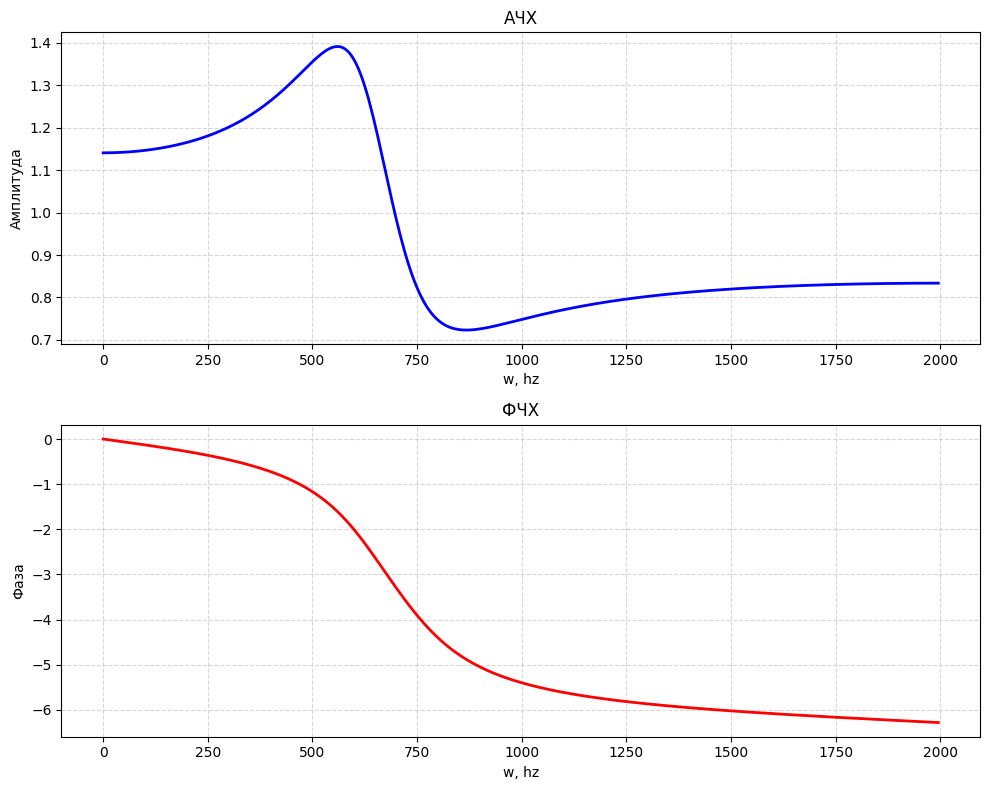

In [11]:
f_hz = (w * fd) / (2 * np.pi)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.plot(f_hz, ach, color='blue', linewidth=2)
ax1.set_title('АЧХ', fontsize=12)
ax1.set_xlabel('w, hz', fontsize=10)
ax1.set_ylabel('Амплитуда', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(f_hz, fch, color='red', linewidth=2)
ax2.set_title('ФЧХ', fontsize=12)
ax2.set_xlabel('w, hz', fontsize=10)
ax2.set_ylabel('Фаза', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

* **Границы основной полосы частот:**  
  От $0$ до fd/2=$5000$ Гц.

* **Соответствие частот:**  
    Связь между угловой частотой и линейной частотой определяется формулой:
    $$\omega = 2\pi f$$
    
    Для нормированной цифровой частоты (в радианах на отсчёт):
    $$\omega = \frac{2\pi f}{f_s}$$



Вычисление переменных для второй части работы.

In [12]:
N = 64
fd = 2000 * (1 + Nvar % 5)
T = 1 / fd
A1 = 1 + 0.01 * Nvar
A2 = 2 * A1
f1 = fd / 8
f2 = 1.5 * f1
print(f"Nvar = {Nvar};\nN    = {N};\nfd   = {fd};\nT    = {T};\n")

A = np.array([0, A1, A2])
print(f"\nA = {A};\n")
f = np.array([0, f1, f2])
print(f"\nf = {f};")

Nvar = 4;
N    = 64;
fd   = 10000;
T    = 0.0001;


A = [0.   1.04 2.08];


f = [   0. 1250. 1875.];


2.1

In [13]:
NA = np.arange(N)
x = A1 * np.cos(2 * np.pi * f1 * NA / fd + np.pi/4) + A2 * np.cos(2 * np.pi * f2 * NA / fd + np.pi/8)

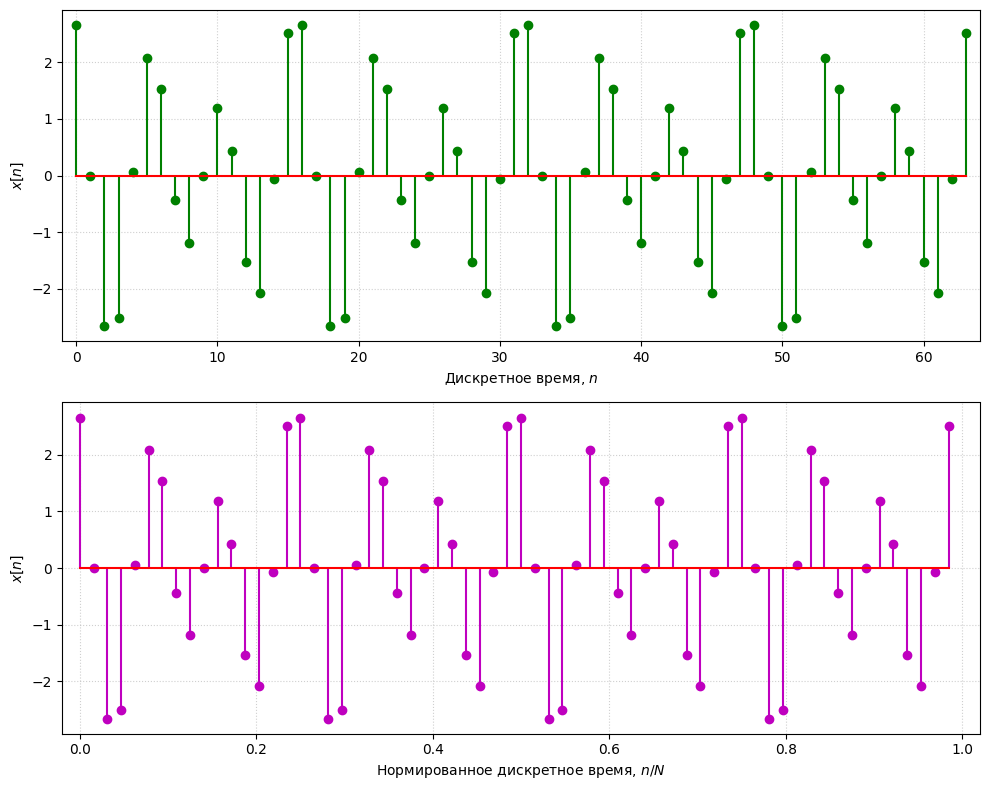

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.stem(NA, x, linefmt='g-', markerfmt='go', basefmt='r-')
ax1.set_xlabel('Дискретное время, $n$', fontsize=10)
ax1.set_ylabel('$x[n]$', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(-1, N)

NN = NA / N

ax2.stem(NN, x, linefmt='m-', markerfmt='mo', basefmt='r-')
ax2.set_xlabel('Нормированное дискретное время, $n/N$', fontsize=10)
ax2.set_ylabel('$x[n]$', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)

plt.tight_layout()
plt.show()

2.2

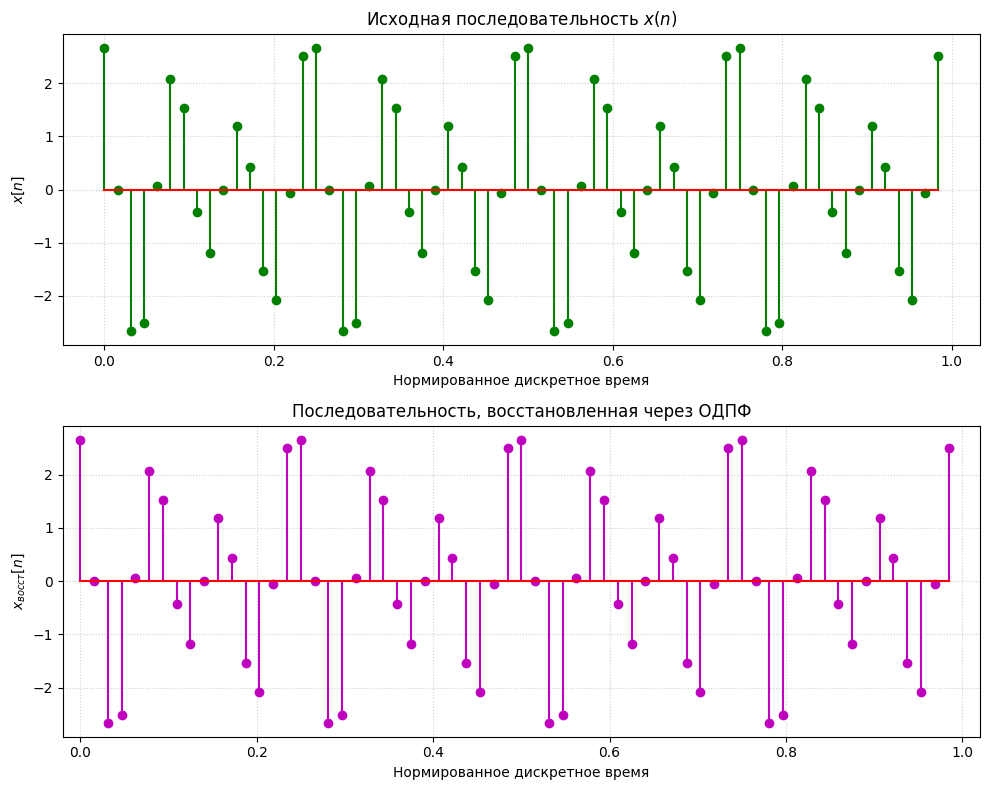

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.stem(NN, x, linefmt='g-', markerfmt='go', basefmt='r-')
ax1.set_title(f'Исходная последовательность $x(n)$', fontsize=12)
ax1.set_xlabel('Нормированное дискретное время', fontsize=10)
ax1.set_ylabel('$x[n]$', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)

ax2.stem(NN, np.fft.ifft(np.fft.fft(x)).real, linefmt='m-', markerfmt='mo', basefmt='r-')
ax2.set_title('Последовательность, восстановленная через ОДПФ', fontsize=12)
ax2.set_xlabel('Нормированное дискретное время', fontsize=10)
ax2.set_ylabel('$x_{восст}[n]$', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)

plt.tight_layout()
plt.show()

2.3

In [16]:
X_spec = np.fft.fft(x)
X_amplitude = np.abs(X_spec) / N
X_phase_prep = np.angle(X_spec)
X_phase = np.where(X_amplitude > 1e-6, X_phase_prep, 0) # Исправление для angle от 0.00000000000000003(фича double = 0)

kA = np.arange(N)
kN = kA / N
kF = kA * (fd / N)

In [17]:
peak_indices = np.where(X_amplitude > 0.1)[0]

print(f"{'Бин (k)':<10} | {'Норм. частота (рад)':<22} | {'Абс. частота (Гц)':<20} | {'Амплитуда':<10}")
print("-" * 70)

for k in peak_indices:
    frac = Fraction(2 * int(k), int(N))
    if frac == 0:
        w_str = "0"
    elif frac.denominator == 1:
        w_str = "π" if frac.numerator == 1 else f"{frac.numerator}π"
    else:
        w_str = f"{frac.numerator}/{frac.denominator}π"
        
    print(f"{k:<10} | {w_str:<22} | {kF[k]:<20.2f} | {X_amplitude[k]:<10.4f}")

Бин (k)    | Норм. частота (рад)    | Абс. частота (Гц)    | Амплитуда 
----------------------------------------------------------------------
8          | 1/4π                   | 1250.00              | 0.5200    
12         | 3/8π                   | 1875.00              | 1.0400    
52         | 13/8π                  | 8125.00              | 1.0400    
56         | 7/4π                   | 8750.00              | 0.5200    


In [18]:
peak_indices = np.where(abs(X_phase) > 0.1)[0]

print(f"{'Бин (k)':<10} | {'Норм. частота (рад)':<22} | {'Абс. частота (Гц)':<20} | {'Фаза':<10}")
print("-" * 70)

for k in peak_indices:
    frac = Fraction(2 * int(k), int(N))
    if frac == 0:
        w_str = "0"
    elif frac.denominator == 1:
        w_str = "π" if frac.numerator == 1 else f"{frac.numerator}π"
    else:
        w_str = f"{frac.numerator}/{frac.denominator}π"
        
    print(f"{k:<10} | {w_str:<22} | {kF[k]:<20.2f} | {X_phase[k]:<10.4f}")

Бин (k)    | Норм. частота (рад)    | Абс. частота (Гц)    | Фаза      
----------------------------------------------------------------------
8          | 1/4π                   | 1250.00              | 0.7854    
12         | 3/8π                   | 1875.00              | 0.3927    
52         | 13/8π                  | 8125.00              | -0.3927   
56         | 7/4π                   | 8750.00              | -0.7854   


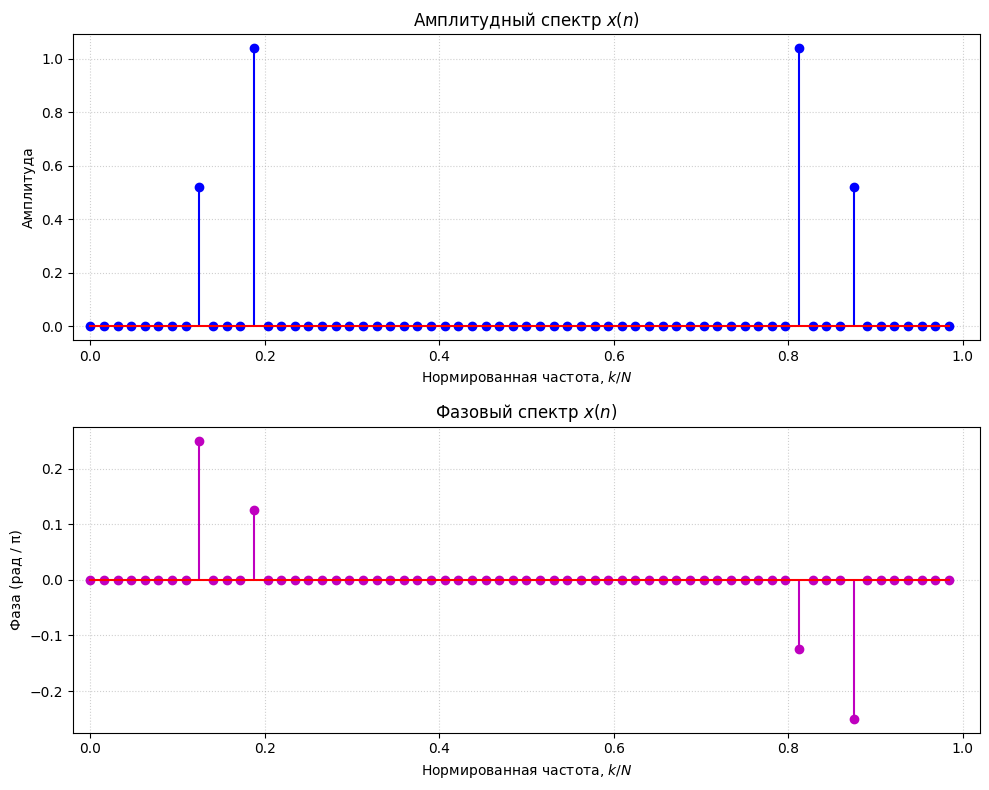

In [19]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.stem(kN, X_amplitude, linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title('Амплитудный спектр $x(n)$', fontsize=12)
ax1.set_xlabel('Нормированная частота, $k/N$', fontsize=10)
ax1.set_ylabel('Амплитуда', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(-0.02, 1.02)

ax2.stem(kN, X_phase / np.pi, linefmt='m-', markerfmt='mo', basefmt='r-')
ax2.set_title('Фазовый спектр $x(n)$', fontsize=12)
ax2.set_xlabel('Нормированная частота, $k/N$', fontsize=10)
ax2.set_ylabel('Фаза (рад / π)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)
#ax2.set_yticks([-np.pi/8, -np.pi/12, -np.pi/16, 0, np.pi/16, np.pi/12, np.pi/8])
#ax2.set_yticklabels(['-π/4', '-π/6', '-π/8', '0', 'π/8', 'π/6', 'π/4'])

plt.tight_layout()
plt.show()

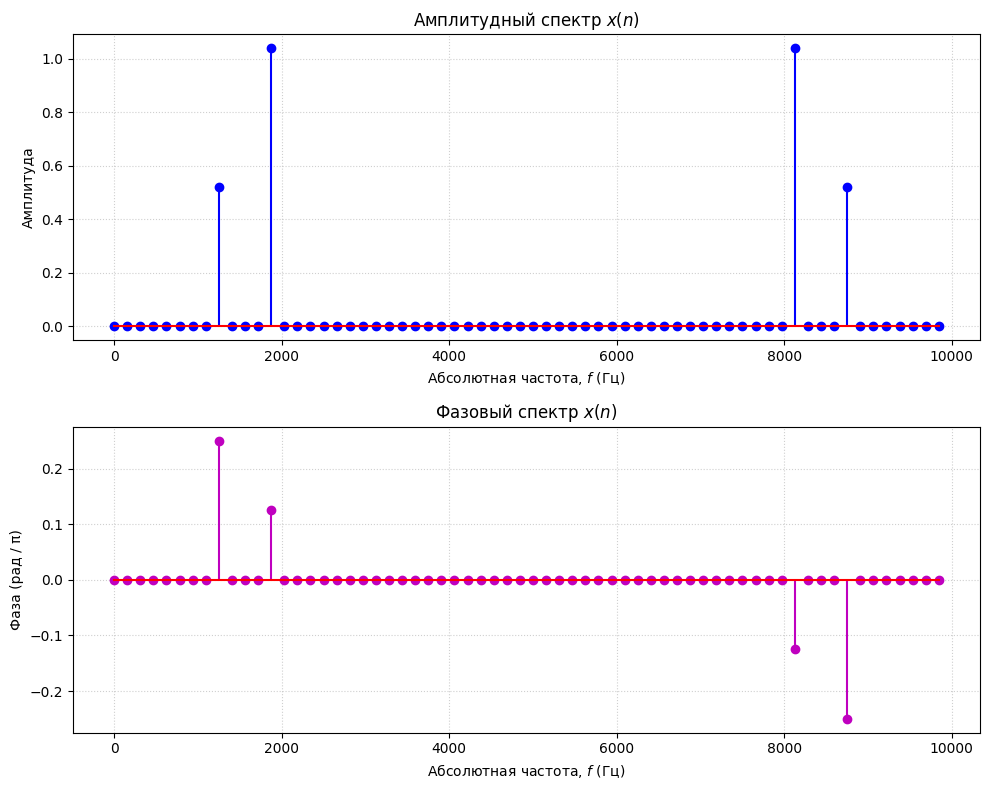

In [20]:
fig2, (ax3, ax4) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax3.stem(kF, X_amplitude, linefmt='b-', markerfmt='bo', basefmt='r-')
ax3.set_title('Амплитудный спектр $x(n)$', fontsize=12)
ax3.set_xlabel('Абсолютная частота, $f$ (Гц)', fontsize=10)
ax3.set_ylabel('Амплитуда', fontsize=10)
ax3.grid(True, linestyle=':', alpha=0.6)

ax4.stem(kF, X_phase / np.pi, linefmt='m-', markerfmt='mo', basefmt='r-')
ax4.set_title('Фазовый спектр $x(n)$', fontsize=12)
ax4.set_xlabel('Абсолютная частота, $f$ (Гц)', fontsize=10)
ax4.set_ylabel('Фаза (рад / π)', fontsize=10)
ax4.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


* **Связь дискретного нормированного времени с дискретным временем:**  
  Задается формулой $NN = \frac{NA}{N} = \frac{NA}{24}$. Дискретное время $NA$ представляет собой целые номера отсчетов от $0$ до $23$, а нормированное время $NN$ переводит их в доли периода от $0$ до $1$.

* **Связь частоты $k_F$ (Гц) с дискретной нормированной частотой $k_N$:**  

$$k_N = \frac{k_A}{N}$$

$$k_F = k_A \cdot \frac{f_d}{N} = k_N \cdot f_d$$

* **Вид амплитудного и фазового спектров:**  
  * **Амплитудный спектр:** содержит два выраженных симметричных пика на частотах гармоник $f_1$ и $f_2$ в первой половине спектра (до $f_d/2 = 5000$ Гц) и два зеркальных пика во второй половине (после $5000$ Гц). Высота пиков пропорциональна амплитудам $A_1$ и $A_2$.
  * **Фазовый спектр:** точки пиков идентичны амплитудному спектру, но они зеркальны от половины спектра, а не симметричны и строго убывают.

2.4

In [21]:
XMP = np.abs(X_spec)
XAP = X_spec_magnitude = np.abs(X_spec) / N

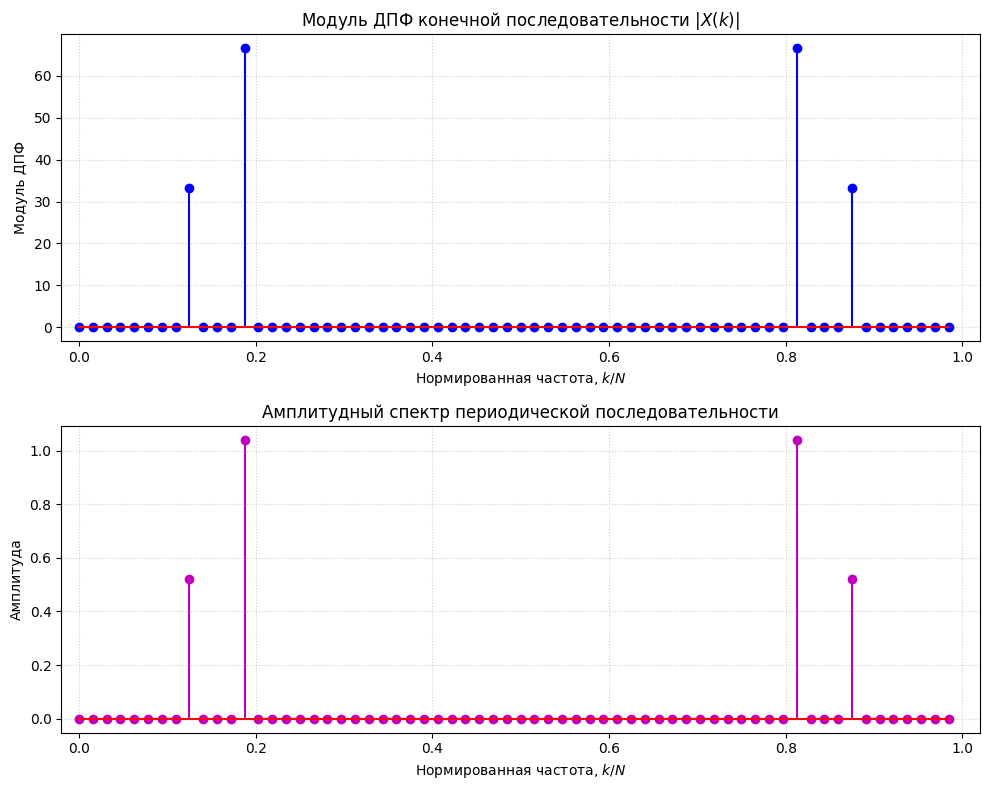

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=100)

ax1.stem(kN, XMP, linefmt='b-', markerfmt='bo', basefmt='r-')
ax1.set_title('Модуль ДПФ конечной последовательности $|X(k)|$', fontsize=12)
ax1.set_xlabel('Нормированная частота, $k/N$', fontsize=10)
ax1.set_ylabel('Модуль ДПФ', fontsize=10)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(-0.02, 1.02)

ax2.stem(kN, XAP, linefmt='m-', markerfmt='mo', basefmt='r-')
ax2.set_title('Амплитудный спектр периодической последовательности', fontsize=12)
ax2.set_xlabel('Нормированная частота, $k/N$', fontsize=10)
ax2.set_ylabel('Амплитуда', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)

plt.tight_layout()
plt.show()

Связь спектров задаётся формулой масштабирования $A(k) = |X(k)| / N$, размерность выборки равна $N = 64$.

В спектре исследуемой смеси сигналов наблюдаются два выраженных дискретных пика в первой половине периода ДПФ (до частоты $k/N = 0.5$) и два их зеркальных симметричных отражения во второй половине:
*   Первый пик на частоте $k/N \approx 0.125$ имеет значение модуля ДПФ $\approx 33.5$, что после нормировки соответствует спектральной амплитуде периодического сигнала $\approx 0.53$.
*   Второй пик на частоте $k/N \approx 0.188$ имеет значение модуля ДПФ $\approx 64$, что после нормировки соответствует спектральной амплитуде периодического сигнала $\approx 1.07$.


2.5

In [23]:
k_indices = np.arange(-int(N/2), int(N/2))
X_a = np.zeros(N, dtype=complex)

for idx, k in enumerate(k_indices):
    if -N/2 <= k <= -1:
        X_a[idx] = X_spec[N + k]
    elif 0 <= k <= N/2 - 1:
        X_a[idx] = X_spec[k]

t_axis = np.arange(0, (N - 1) * T + 0.001, 0.25 * T)

x_analog_recovered = np.zeros(len(t_axis))
for idx_t, t in enumerate(t_axis):
    sum_harmonics = 0.0
    for idx_k, k in enumerate(k_indices):
        val = X_a[idx_k] * np.exp(1j * (2 * np.pi / (N * T)) * k * t)
        sum_harmonics += val
    x_analog_recovered[idx_t] = sum_harmonics.real / N

x_ideal_analog = A[1] * np.cos(2 * np.pi * f[1] * t_axis + np.pi/4) + A[2] * np.cos(2 * np.pi * f[2] * t_axis + np.pi/8)

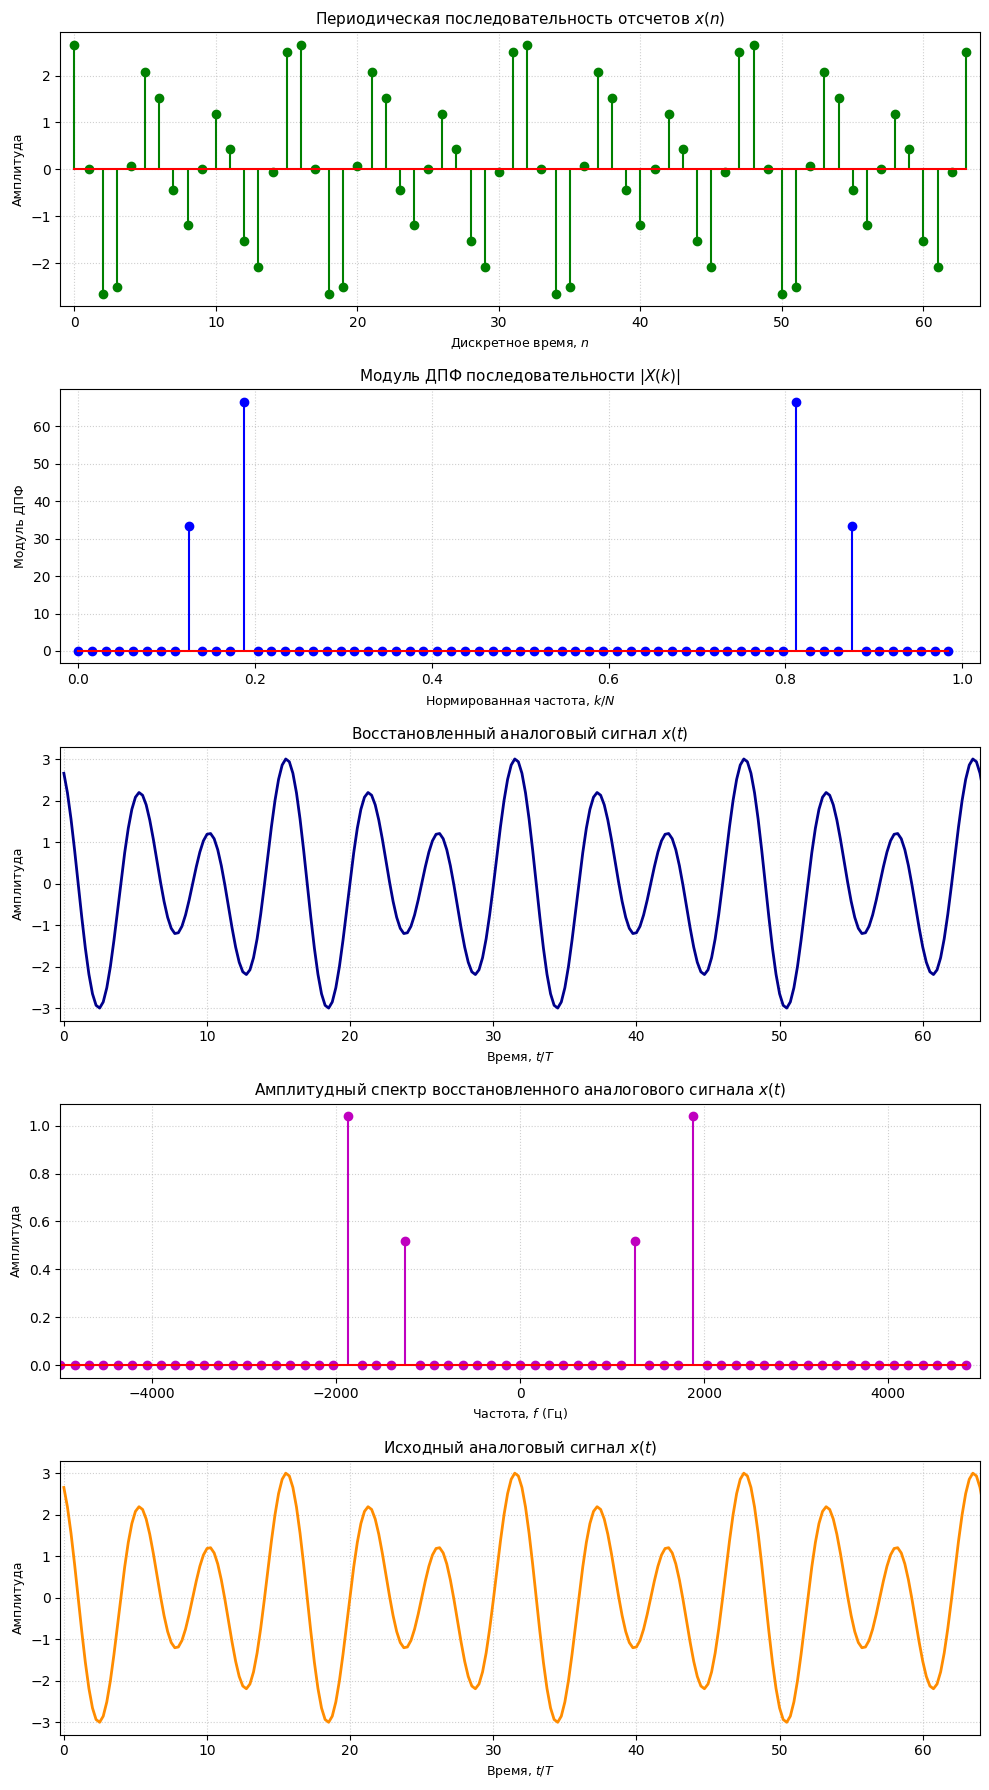

In [24]:
fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, 1, figsize=(10, 18), dpi=100)

ax1.stem(NA, x, linefmt='g-', markerfmt='go', basefmt='r-')
ax1.set_title('Периодическая последовательность отсчетов $x(n)$', fontsize=11)
ax1.set_xlabel('Дискретное время, $n$', fontsize=9)
ax1.set_ylabel('Амплитуда', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_xlim(-1, N)

ax2.stem(kN, np.abs(X_spec), linefmt='b-', markerfmt='bo', basefmt='r-')
ax2.set_title('Модуль ДПФ последовательности $|X(k)|$', fontsize=11)
ax2.set_xlabel('Нормированная частота, $k/N$', fontsize=9)
ax2.set_ylabel('Модуль ДПФ', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_xlim(-0.02, 1.02)


ax3.plot(t_axis / T, x_analog_recovered, color='darkblue', linewidth=2)
ax3.set_title('Восстановленный аналоговый сигнал $x(t)$', fontsize=11)
ax3.set_xlabel('Время, $t/T$', fontsize=9)
ax3.set_ylabel('Амплитуда', fontsize=9)
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.set_xlim(-1/4, N)


f_analog_axis = k_indices * (fd / N)
ax4.stem(f_analog_axis, np.abs(X_a) / N, linefmt='m-', markerfmt='mo', basefmt='r-')
ax4.set_title('Амплитудный спектр восстановленного аналогового сигнала $x(t)$', fontsize=11)
ax4.set_xlabel('Частота, $f$ (Гц)', fontsize=9)
ax4.set_ylabel('Амплитуда', fontsize=9)
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.set_xlim(-fd / 2, fd / 2)


ax5.plot(t_axis / T, x_ideal_analog, color='darkorange', linewidth=2)
ax5.set_title('Исходный аналоговый сигнал $x(t)$', fontsize=11)
ax5.set_xlabel('Время, $t/T$', fontsize=9)
ax5.set_ylabel('Амплитуда', fontsize=9)
ax5.grid(True, linestyle=':', alpha=0.6)
ax5.set_xlim(-1/4, N)

plt.tight_layout()
plt.show()


2.6

* **Связь модуля ДПФ последовательности со спектром аналогового сигнала:**  
  Разница y1/y2 = N, поскольку амплитудный спектр восстановленного сигнала получается делением модуля ДПФ на N. По оси X первая половина остаётся прежней, но смещается в право из-за того, что происходит с правой, а она сдвигается на 2π(циклично). Проще говоря половины меняются местами.

* **Результат визуального сравнения восстановленного и исходного сигналов:**  
  Визуально разницы не видно.

2.7

In [25]:
ET = np.sum(np.abs(x)**2)
EF = np.sum(np.abs(X_spec)**2) / N
print(f"Расхождение: {np.abs(ET - EF)}")
print(f"Равенство Парсеваля is {np.isclose(ET, EF)}")

Расхождение: 2.842170943040401e-14
Равенство Парсеваля is True


* **Физический смысл:** Равенство Парсеваля выражает фундаментальный закон сохранения энергии. Полная энергия (мощность) дискретного процесса во временной области эквивалентна суммарной энергии его спектральных компонент в частотной области. Масштабирующий множитель $1/N$ компенсирует суммирование по $N$ отсчетам. В ходе программной проверки энергии временной и частотной областей совпали с точностью до рассчётной погрешности 1e-14.

## Выводы

### 1. Линейные дискретные системы (Часть 1)
* **Реакция системы на сигнал:** В ходе выполнения работы был рассчитан выходной сигнал двумя способами — через свёртку с импульсной характеристикой и напрямую по разностному уравнению. На интервале действия входного импульса ($N_2 = 34$ отсчёта) оба способа дают визуально неразличимый результат, но полная свёртка дополнительно показывает «хвост» свободных затухающих колебаний системы после окончания сигнала.
* **Устойчивость фильтра:** После расчёта нулей и полюсов передаточной функции $H(z)$ была проверена устойчивость системы. Так как модули обоих полюсов меньше единицы ($|p_1| = |p_2| = 0.8149 < 1$) и на комплексной плоскости они лежат внутри единичной окружности, система устойчива.
* **Частотные свойства (АЧХ и ФЧХ):** На основе построенных графиков АЧХ и ФЧХ в нормированной шкале и в герцах было установлено, что система работает как фильтр нижних частот: она пропускает низкочастотные составляющие сигнала и сильно подавляет высокие частоты, а положение нулей и полюсов задаёт характер спада АЧХ.

### 2. Спектральный анализ и ДПФ (Часть 2)
* **Обратимость ДПФ:** Периодическая последовательность из двух косинусоид была разложена в спектр с помощью прямого ДПФ, а затем восстановлена обратно через ОДПФ — исходный и восстановленный сигналы полностью совпали.
* **Амплитудный и фазовый спектры:** На графиках в шкалах нормированных и абсолютных частот чётко выделились пики на частотах заданных гармоник и их зеркальные копии во второй половине периода. При этом амплитудный спектр оказался симметричным, а фазовый — зеркальным(антисимметричным).
* **Связь дискретного и аналогового спектров:** Для перехода от модуля ДПФ $|X(k)|$ к реальным амплитудам аналогового сигнала значения спектра были разделены на длину выборки $N = 64$, а отрицательные частоты перенесены влево относительно нуля. Восстановленный по этим гармоникам непрерывный сигнал $x(t)$ визуально полностью совпал с исходным аналоговым сигналом.
* **Закон сохранения энергии:** Проверка равенства Парсеваля подтвердила, что энергия сигнала во времени равна его энергии в частотной области (с точностью погрешности $2.84 \cdot 10^{-14}$), следовательно, преобразование Фурье не теряет и не искажает энергию сигнала.